# Install and import libraries

In [1]:
import nltk
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import movie_reviews
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

nltk.download("movie_reviews")

[nltk_data] Downloading package movie_reviews to
[nltk_data]     C:\Users\yuvan\AppData\Roaming\nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!


True

# Load and inspect the dataset

In [2]:
# Get all review IDs
review_ids = movie_reviews.fileids()

texts = [
    " ".join(movie_reviews.words(fileid))
    for fileid in review_ids
]

labels = [
    movie_reviews.categories(fileid)[0]
    for fileid in review_ids
]

df = pd.DataFrame({
    'review': texts,
    'sentiment': labels
})

print(df.shape)
print(df['sentiment'].value_counts())

display(df.head())

(2000, 2)
sentiment
neg    1000
pos    1000
Name: count, dtype: int64


,review,sentiment
0,"plot : two teen couples go to a church party ,...",neg
1,the happy bastard ' s quick movie review damn ...,neg
2,it is movies like these that make a jaded movi...,neg
3,""" quest for camelot "" is warner bros . ' first...",neg
4,synopsis : a mentally unstable man undergoing ...,neg


In [3]:
# inspect one review 

print(df.loc[0,'review'][:])
print(df.loc[0,'sentiment'])

plot : two teen couples go to a church party , drink and then drive . they get into an accident . one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . what ' s the deal ? watch the movie and " sorta " find out . . . critique : a mind - fuck movie for the teen generation that touches on a very cool idea , but presents it in a very bad package . which is what makes this review an even harder one to write , since i generally applaud films which attempt to break the mold , mess with your head and such ( lost highway & memento ) , but there are good and bad ways of making all types of films , and these folks just didn ' t snag this one correctly . they seem to have taken this pretty neat concept , but executed it terribly . so what are the problems with the movie ? well , its main problem is that it ' s simply too jumbled . it starts off " normal " but then downshifts into this " fantasy " world in which you , as an audience member , have no idea

# Split the dataset

In [4]:
x_train,x_test,y_train,y_test = train_test_split(
    df['review'],
    df['sentiment'],
    test_size= 0.2,
    random_state=42,
    stratify= df['sentiment']
)

print('Train & Test Samples: ',len(x_train),' ',len(x_test))
print("distribution of the sentiment: ")
print(y_train.value_counts())
print(y_test.value_counts())

Train & Test Samples:  1600   400
distribution of the sentiment: 
sentiment
pos    800
neg    800
Name: count, dtype: int64
sentiment
neg    200
pos    200
Name: count, dtype: int64


# Build the three models

In [5]:
models = {
    "Logistic Regression" : LogisticRegression(max_iter=2000),
    "Naive Bayes" : MultinomialNB(),
    "Linear SVM" : LinearSVC()
}

# TfidfVectorizer: converts reviews into weighted numerical features.
# ngram_range=(1, 2): captures individual words and two-word phrases.
# min_df=2: ignores terms appearing in fewer than two training documents.
# Pipeline: fits TF-IDF only on training data and then trains the classifier.

# Train and evaluate all models

In [6]:
results = []
trained_models = {}

for name,classifer in models.items():

    print()
    print('Training: ',name)
    print()

    pipeline = Pipeline([
        (
            'tfidf',
            TfidfVectorizer(
                lowercase=True,
                min_df=2,
                max_df=0.95,
                ngram_range=(1, 2),
                sublinear_tf=True
            )
        ),
        ('classifier', classifer)
    ])

    pipeline.fit(x_train,y_train)

    y_pred = pipeline.predict(x_test)

    # Evaluate
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="pos"
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="pos"
        ),
        "F1 Score": f1_score(
            y_test, y_pred, pos_label="pos"
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro"
        )
    })

    trained_models[name] = pipeline

    print(classification_report(
        y_test,
        y_pred,
        labels=["neg", "pos"],
        target_names=["Negative", "Positive"],
        zero_division=0
    ))

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
                    by="Macro F1",
                    ascending=False
                    ).reset_index(drop=True)

    results_df.round(4)


Training:  Logistic Regression

              precision    recall  f1-score   support

    Negative       0.86      0.85      0.85       200
    Positive       0.85      0.86      0.86       200

    accuracy                           0.85       400
   macro avg       0.86      0.85      0.85       400
weighted avg       0.86      0.85      0.85       400


Training:  Naive Bayes

              precision    recall  f1-score   support

    Negative       0.88      0.81      0.84       200
    Positive       0.82      0.89      0.85       200

    accuracy                           0.84       400
   macro avg       0.85      0.84      0.84       400
weighted avg       0.85      0.84      0.84       400


Training:  Linear SVM

              precision    recall  f1-score   support

    Negative       0.88      0.86      0.87       200
    Positive       0.86      0.89      0.87       200

    accuracy                           0.87       400
   macro avg       0.87      0.87      0.87   

# Visualize the comparison

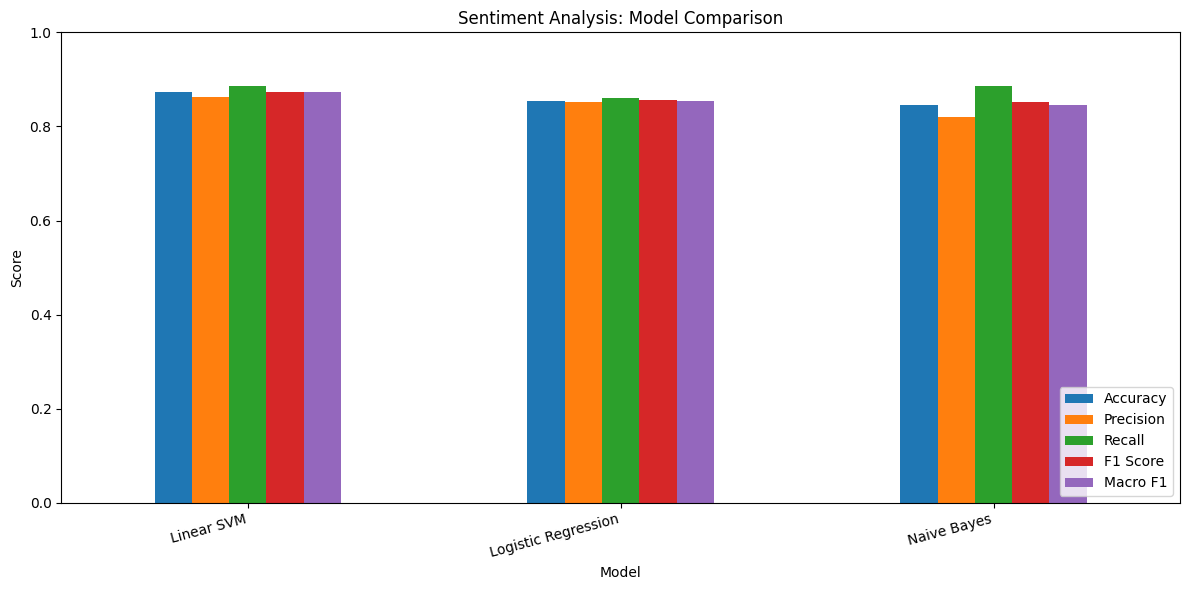

In [7]:
plot_df = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "Macro F1"]
]

plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Sentiment Analysis: Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

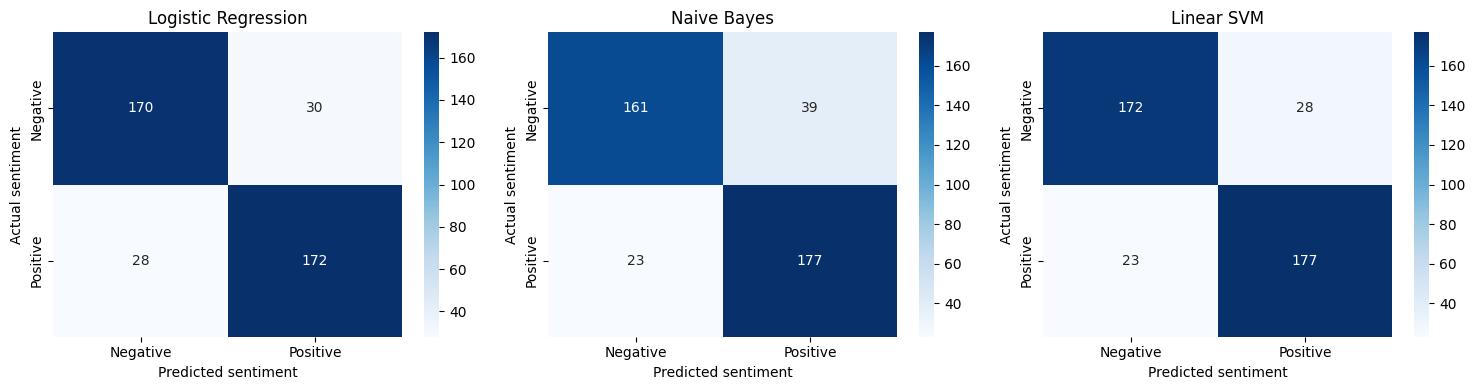

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pipeline) in zip(axes, trained_models.items()):

    y_pred = pipeline.predict(x_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["neg", "pos"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted sentiment")
    ax.set_ylabel("Actual sentiment")

plt.tight_layout()
plt.show()

In [9]:
results_df

,Model,Accuracy,Precision,Recall,F1 Score,Macro F1
0,Linear SVM,0.8725,0.863415,0.885,0.874074,0.872480
1,Logistic Regression,0.8550,0.851485,0.860,0.855721,0.854996
2,Naive Bayes,0.8450,0.819444,0.885,0.850962,0.844752


In [10]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred = best_model.predict(x_test)

errors = pd.DataFrame({
    "review": x_test,
    "actual": y_test,
    "predicted": y_pred
})

errors = errors[
    errors["actual"] != errors["predicted"]
]

print("Best model:", best_model_name)
print("Number of errors:", len(errors))

for _, row in errors.head(5).iterrows():
    print("\n" + "-" * 80)
    print("Actual:", row["actual"])
    print("Predicted:", row["predicted"])
    print("Review:", row["review"][:700])

Best model: Linear SVM
Number of errors: 51

--------------------------------------------------------------------------------
Actual: neg
Predicted: pos
Review: running time approximately 1hr 40mins reviewed by jack choo rating : the movie starts with a rather se7en - ish opening sequence , rather cool and sets the mood for things to come . the story propels the audience into a neo - reality ; somewhat very close to conscious reality but laced with weird tinges of blue and red . existenz is actually the name of a new virtual - reality game . supposedly , vr games are highly popular as is considered a legal - drug in this neo - reality . * * * * ( leigh ) is the ultimate game creator and introduces her ultimate game - experience in the form of existenz . players are required to have bio - ports embedded in their spine , which plugs to a game - pod in

--------------------------------------------------------------------------------
Actual: pos
Predicted: neg
Review: " take a number , fil

In [11]:
new_reviews = [
    "This movie was fantastic, with excellent acting and a brilliant story.",
    "The movie was boring, poorly written, and a complete waste of time.",
    "The film was released last Friday and runs for two hours."
]

predictions = best_model.predict(new_reviews)

for review, sentiment in zip(new_reviews, predictions):
    print(f"\nReview: {review}")
    print(f"Predicted sentiment: {sentiment}")


Review: This movie was fantastic, with excellent acting and a brilliant story.
Predicted sentiment: pos

Review: The movie was boring, poorly written, and a complete waste of time.
Predicted sentiment: neg

Review: The film was released last Friday and runs for two hours.
Predicted sentiment: pos


In [12]:
import joblib

joblib.dump(best_model, "movie_sentiment_model.joblib")

print("Model saved successfully.")

Model saved successfully.


In [13]:
loaded_model = joblib.load("movie_sentiment_model.joblib")

print(
    loaded_model.predict([
        "An excellent movie with a memorable performance."
    ])
)

['pos']


# Oversampling

## 📘 Random Oversampling — Short Notes

Definition: Random Oversampling is a technique used to handle class imbalance by randomly duplicating samples from the minority class.

Purpose:

- Balance the class distribution in the training dataset.
- Help the model learn minority-class patterns better.
- Potentially improve minority-class recall and F1-score.
- Reduce bias toward the majority class.

Working:

1. Identify the minority class.
2. Randomly select samples from that class.
3. Duplicate samples until the desired class balance is achieved.

Advantages:

- Simple and easy to implement.
- Preserves original samples and their labels.

Disadvantages:

- May cause overfitting due to duplicated samples.
- Increases training data size.

Important points:

- Apply oversampling only to training data, never to the test set.
- It is usually unnecessary for an already balanced dataset.
- It duplicates existing data; it does not generate new information.

Example: If a dataset contains 800 positive and 200 negative samples, oversampling can duplicate negative samples until both classes contain 800 samples.

In [14]:
# now our dataset is already doing good 1000 pos 1000 neg 
# so just doing for future use 

# extract the pre exisitng model 

from sklearn.base import clone 
from imblearn.over_sampling import RandomOverSampler

tfidf = loaded_model.named_steps['tfidf']
original_svm = loaded_model.named_steps['classifier']

In [17]:
x_train_tfidf = tfidf.transform(x_train)
x_test_tfidf = tfidf.transform(x_test)

print("Training shape:", x_train_tfidf.shape)
print("Testing shape:", x_test_tfidf.shape)

Training shape: (1600, 116440)
Testing shape: (400, 116440)


In [18]:
ros = RandomOverSampler(random_state=42)

x_train_resampled, y_train_resampled = ros.fit_resample(
    x_train_tfidf,
    y_train
)

print("Before:", y_train.value_counts().to_dict())
print("After:", y_train_resampled.value_counts().to_dict())

Before: {'pos': 800, 'neg': 800}
After: {'pos': 800, 'neg': 800}


In [19]:
svm_resampled = clone(original_svm)

svm_resampled.fit(x_train_resampled, y_train_resampled)

y_pred_resampled = svm_resampled.predict(x_test_tfidf)

print(classification_report(y_test, y_pred_resampled))

              precision    recall  f1-score   support

         neg       0.88      0.86      0.87       200
         pos       0.86      0.89      0.87       200

    accuracy                           0.87       400
   macro avg       0.87      0.87      0.87       400
weighted avg       0.87      0.87      0.87       400



In [20]:
y_pred_original = loaded_model.predict(x_test)

comparison = pd.DataFrame({
    "Model": ["Original SVM", "Oversampled SVM"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_original),
        accuracy_score(y_test, y_pred_resampled)
    ],
    "Macro F1": [
        f1_score(y_test, y_pred_original, average="macro"),
        f1_score(y_test, y_pred_resampled, average="macro")
    ]
})

comparison.round(4)

,Model,Accuracy,Macro F1
0,Original SVM,0.8725,0.8725
1,Oversampled SVM,0.8725,0.8725


Random Oversampling Experiment: The training dataset contained 800 positive and 800 negative reviews. Since the classes were already balanced using stratified train/test splitting, RandomOverSampler did not change the sample distribution. Consequently, the original and resampled Linear SVM models achieved identical accuracy (87.25%) and Macro F1 (0.8725). Oversampling was unnecessary for this dataset.

# Pretrained BERT for Sentiment Analysis.

In [21]:
# Pretrained BERT = a language model that has already learned general language patterns and can be adapted to a specific NLP task.

In [22]:
import torch
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1

print("Device:", "CUDA GPU" if device == 0 else "CPU")

Y:\Python\AI ML\Month 2\week 7-Deep Learning\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: CUDA GPU


In [23]:
sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="lvwerra/distilbert-imdb",
    device=device
)

Y:\Python\AI ML\Month 2\week 7-Deep Learning\.venv\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\yuvan\.cache\huggingface\hub\models--lvwerra--distilbert-imdb. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Y:\Python\AI ML\Month 2\week 7-Deep Learning\.venv\lib\site-packages\huggingface_hub\file_down

In [24]:
positive_review = (
    "This movie was an absolute masterpiece! "
    "The acting was brilliant and the story was captivating."
)

negative_review = (
    "This movie was a complete disaster. "
    "The acting was terrible and the story was painfully boring."
)

positive_result = sentiment_pipeline(positive_review)
negative_result = sentiment_pipeline(negative_review)

print("Positive review:", positive_result)
print("Negative review:", negative_result)

Positive review: [{'label': 'POSITIVE', 'score': 0.9957982897758484}]
Negative review: [{'label': 'NEGATIVE', 'score': 0.9971736669540405}]


In [25]:
# Convert pandas Series to a list of raw strings
x_test_text = x_test.tolist()

In [26]:
# BERT inference in batches
bert_results = sentiment_pipeline(
    x_test_text,
    batch_size=16,
    truncation=True
)

bert_predictions = [
    result["label"].lower()
    for result in bert_results
]

print("Number of predictions:", len(bert_predictions))

Number of predictions: 400


In [28]:
# Check the label mapping before calculating metrics:

print("BERT label mapping:", sentiment_pipeline.model.config.id2label)
print("Actual labels:", sorted(y_test.unique()))

BERT label mapping: {0: 'NEGATIVE', 1: 'POSITIVE'}
Actual labels: ['neg', 'pos']


In [29]:
label_map = {
    "positive": "pos",
    "negative": "neg",
    "pos": "pos",
    "neg": "neg"
}

bert_predictions = [
    label_map[pred] for pred in bert_predictions
]

In [32]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

print(classification_report(
    y_test,
    bert_predictions,
    labels=["neg", "pos"],
    target_names=["Negative", "Positive"]
))

print("BERT Accuracy:", accuracy_score(y_test, bert_predictions))
print(
    "BERT Macro F1:",
    f1_score(y_test, bert_predictions, average="macro")
)

              precision    recall  f1-score   support

    Negative       0.86      0.88      0.87       200
    Positive       0.88      0.86      0.87       200

    accuracy                           0.87       400
   macro avg       0.87      0.87      0.87       400
weighted avg       0.87      0.87      0.87       400

BERT Accuracy: 0.87
BERT Macro F1: 0.8699869986998701


In [33]:
svm_predictions = loaded_model.predict(x_test)

comparison = pd.DataFrame({
    "Model": ["Linear SVM (TF-IDF)", "Pretrained BERT"],
    "Accuracy": [
        accuracy_score(y_test, svm_predictions),
        accuracy_score(y_test, bert_predictions)
    ],
    "Macro F1": [
        f1_score(y_test, svm_predictions, average="macro"),
        f1_score(y_test, bert_predictions, average="macro")
    ]
})

comparison.round(4)

,Model,Accuracy,Macro F1
0,Linear SVM (TF-IDF),0.8725,0.8725
1,Pretrained BERT,0.8700,0.8700


# VADER Sentiment Analysis

In [34]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download("vader_lexicon")

sia = SentimentIntensityAnalyzer()

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\yuvan\AppData\Roaming\nltk_data...


In [35]:
sample_reviews = [
    "This movie was absolutely fantastic! I loved every minute.",
    "The movie was boring, disappointing, and a complete waste of time.",
    "The movie was okay, but nothing special."
]

for review in sample_reviews:
    scores = sia.polarity_scores(review)
    print("Review:", review)
    print("Scores:", scores)
    print()

Review: This movie was absolutely fantastic! I loved every minute.
Scores: {'neg': 0.0, 'neu': 0.418, 'pos': 0.582, 'compound': 0.8542}

Review: The movie was boring, disappointing, and a complete waste of time.
Scores: {'neg': 0.542, 'neu': 0.458, 'pos': 0.0, 'compound': -0.8074}

Review: The movie was okay, but nothing special.
Scores: {'neg': 0.309, 'neu': 0.536, 'pos': 0.155, 'compound': -0.3479}



In [36]:
vader_predictions = []

for review in x_test:
    compound = sia.polarity_scores(review)["compound"]

    if compound >= 0.05:
        vader_predictions.append("pos")
    elif compound <= -0.05:
        vader_predictions.append("neg")
    else:
        # Your dataset contains only pos/neg labels.
        # Use the compound score's sign for neutral reviews.
        vader_predictions.append("pos" if compound > 0 else "neg")

In [37]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("VADER Accuracy:", accuracy_score(y_test, vader_predictions))
print("VADER Macro F1:", f1_score(y_test, vader_predictions, average="macro"))

print(classification_report(y_test, vader_predictions))

VADER Accuracy: 0.6225
VADER Macro F1: 0.6071774660345085
              precision    recall  f1-score   support

         neg       0.70      0.42      0.53       200
         pos       0.59      0.82      0.68       200

    accuracy                           0.62       400
   macro avg       0.65      0.62      0.61       400
weighted avg       0.65      0.62      0.61       400



In [38]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

svm_predictions = loaded_model.predict(x_test)

comparison = pd.DataFrame([
    {
        "Model": "Linear SVM (TF-IDF)",
        "Accuracy": accuracy_score(y_test, svm_predictions),
        "Macro F1": f1_score(y_test, svm_predictions, average="macro")
    },
    {
        "Model": "Pretrained BERT",
        "Accuracy": accuracy_score(y_test, bert_predictions),
        "Macro F1": f1_score(y_test, bert_predictions, average="macro")
    },
    {
        "Model": "VADER",
        "Accuracy": accuracy_score(y_test, vader_predictions),
        "Macro F1": f1_score(y_test, vader_predictions, average="macro")
    }
])

comparison.sort_values("Macro F1", ascending=False).reset_index(drop=True)

,Model,Accuracy,Macro F1
0,Linear SVM (TF-IDF),0.8725,0.872480
1,Pretrained BERT,0.8700,0.869987
2,VADER,0.6225,0.607177



```
Linear SVM: TF-IDF features combined with a linear classifier work very well for this movie-review dataset.

Pretrained BERT: Contextual language representations are competitive, but the pretrained model doesn't automatically outperform a traditional ML baseline.

VADER: Its lexicon-and-rule-based approach is less effective on these reviews. Movie reviews can contain complex context, sarcasm, and nuanced opinions that simple sentiment rules struggle to capture.